## Import the neccessary libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
df = pd.read_csv(r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\data\processed_house_rentals.csv")
df.head()

,price,category,bedrooms,bathrooms,location,condition,amenities,region,locality,furnished
0,9196,Flats,2,2,"Greater Accra, East Legon",0,"24-hour Electricity,Air Conditioning,Balcony,C...",Greater Accra,East Legon,1
1,7500,Flats,2,2,"Greater Accra, Dzorwulu",0,"24-hour Electricity,Air Conditioning,Apartment...",Greater Accra,Dzorwulu,0
2,11200,Detached,4,5,"Greater Accra, Ashaley Botwe, Lake Side Estate",2,"Tiled Floor,Chandelier,Dining Area,Balcony,Pop...",Greater Accra,Ashaley Botwe,1
3,2500,Detached,3,3,"Greater Accra, Teshie",0,"Pop Ceiling,Pre-Paid Meter,24-hour Electricity...",Greater Accra,Teshie,1
4,9146,Detached,3,3,"Greater Accra, Spintex",0,"Pre-Paid Meter,Dining Area,Chandelier,Balcony,...",Greater Accra,Spintex,1


## Check for correlation

In [4]:
df_temp = df.copy()  # Make a safe copy
categorical_cols = ['region', 'locality', 'amenities', 'category', 'location']

# Apply target encoding only for analysis
for col in categorical_cols:
    mean_target = df_temp.groupby(col)['price'].mean()
    df_temp[col] = df_temp[col].map(mean_target)


In [5]:
corr = df_temp.corr()['price'].sort_values(ascending=False)
print(corr)


price        1.000000
amenities    0.868362
location     0.595961
locality     0.554808
bathrooms    0.533008
bedrooms     0.496805
category     0.386996
furnished    0.351527
region       0.180029
condition    0.030830
Name: price, dtype: float64


## Visualize the correlation

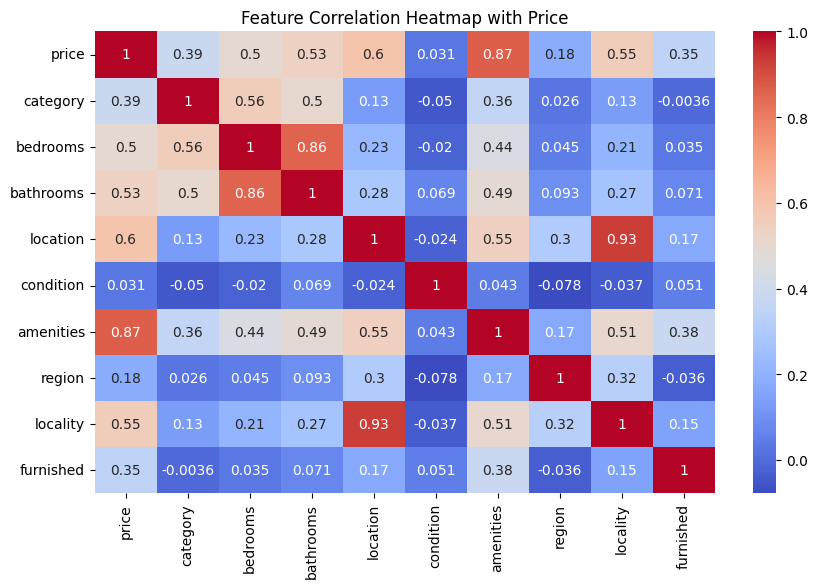

In [6]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_temp.corr(), annot=True, cmap='coolwarm')
plt.title('Feature Correlation Heatmap with Price')
plt.show()


Region and location are least correlated with price so to prevent redundant predictors in our regression model, they have to be dropped. 

In [7]:
df.drop(['condition','region'],axis=1,inplace=True)

## Check for multicollinearity 

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import seaborn as sns
import matplotlib.pyplot as plt

# Choose features highly correlated with the target
high_corr_features = ['bedrooms','bathrooms','locality','location']

# Create a temporary dataframe with only those features
X = df_temp[high_corr_features].drop('price', axis=1, errors='ignore')

# Add constant and compute VIF
X = sm.add_constant(X)

vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

#  Display VIF results
print(vif_data.sort_values(by="VIF", ascending=False))



     Feature       VIF
0      const  8.343723
4   location  7.588766
3   locality  7.500161
2  bathrooms  3.887587
1   bedrooms  3.767890


The Variance Inflation Factor reported that the correlation between location and locality is high. Though not severe, one has to be dropped because a critical look at the dataset reveals some sought of information overlap. Where as the relationship between bathrooms and bedrooms is moderated and could be maintained.

In [9]:
df.drop('location', axis=1, inplace =True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14249 entries, 0 to 14248
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   price      14249 non-null  int64 
 1   category   14249 non-null  object
 2   bedrooms   14249 non-null  int64 
 3   bathrooms  14249 non-null  int64 
 4   amenities  14249 non-null  object
 5   locality   14249 non-null  object
 6   furnished  14249 non-null  int64 
dtypes: int64(4), object(3)
memory usage: 779.4+ KB


## Encoding locality, amenities and category with target mean encoding

#### split the data

In [ ]:
from sklearn.model_selection import train_test_split

# Split into features (X) and target (y)
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


#### Make a temporary copy to calculate mean rents

In [12]:
train_data = X_train.copy()
train_data['price'] = y_train

####  Target encode the categorical columns

In [13]:
# Define categorical columns
categorical_cols = ['category', 'amenities', 'locality']

for col in categorical_cols:
    # Calculate average price for each category in the training data
    category_means = train_data.groupby(col)['price'].mean()

    # Map averages to both train and test sets
    X_train[col] = X_train[col].map(category_means)
    X_test[col] = X_test[col].map(category_means)

    # Handle categories that appear in test but not in train
    X_test[col] = X_test[col].fillna(category_means.mean())

#### Verify that the columns are now numeric

In [14]:
print(X_train[categorical_cols].head(10))

          category     amenities     locality
409    7758.379780  15701.808511  4960.303523
1285   3823.431073   7800.000000  9373.466867
5030   7758.379780  16250.000000  8371.680233
13767  3823.431073   1217.894737  1712.500000
5763   7681.391858   9996.630081  8731.023891
8704   7758.379780   8000.000000  6688.948101
1091   3823.431073  20800.000000  9333.641026
4959   3823.431073   1784.615385  1708.653846
73     3823.431073   2400.000000  2773.432314
2995   3823.431073   5800.000000  8731.023891


In [15]:
print(X_train[categorical_cols].dtypes)

category     float64
amenities    float64
locality     float64
dtype: object


In [16]:
X_train

,category,bedrooms,bathrooms,amenities,locality,furnished
409,7758.379780,4,4,15701.808511,4960.303523,2
1285,3823.431073,1,2,7800.000000,9373.466867,0
5030,7758.379780,4,4,16250.000000,8371.680233,0
13767,3823.431073,1,1,1217.894737,1712.500000,0
5763,7681.391858,3,3,9996.630081,8731.023891,2
...,...,...,...,...,...,...
5191,7758.379780,2,2,12250.000000,6049.068085,2
13418,3823.431073,1,1,1995.454545,5539.527273,0
5390,7681.391858,1,1,750.000000,3645.669872,1
860,11390.029070,4,4,13000.000000,8731.023891,1


## Re-separate the data for more clarity

In [17]:
X_train_final = X_train.copy()
y_train_final = y_train.copy()

X_test_final = X_test.copy()
y_test_final = y_test.copy()


Save the test and data for future use

In [18]:
test_data = pd.concat([X_test_final, y_test_final], axis=1)
test_data.to_csv(r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\data\test_data.csv",index=False)
train_data = pd.concat([X_train_final, y_train_final], axis=1)
train_data.to_csv(r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\data\train_data.csv",index=False)

## Perform normalization

In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)


#### Box Plots To understand Effect Of Standard Scaler

Text(0.5, 1.0, 'X_train After Scaling')

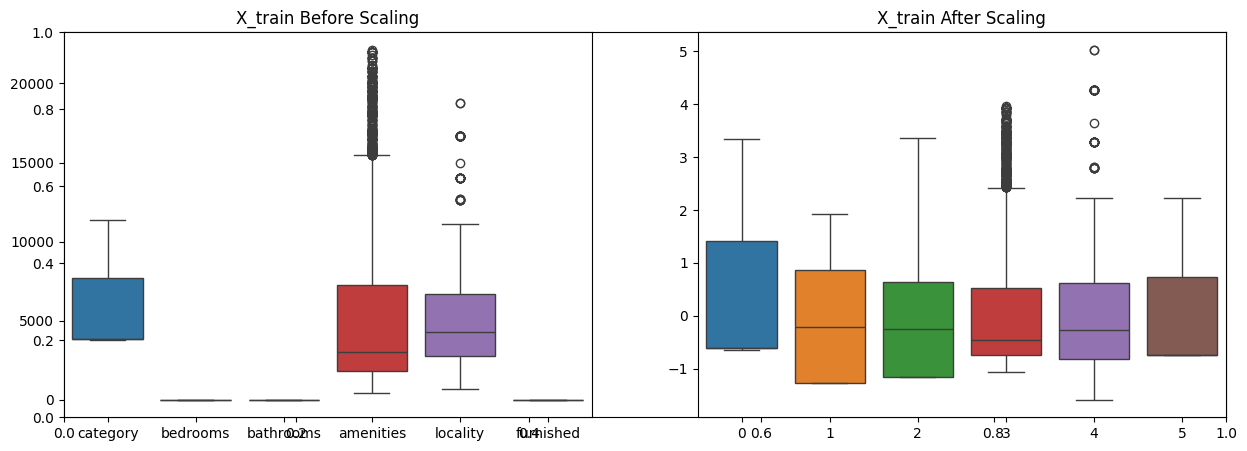

In [21]:
plt.subplots(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train_final)
plt.title('X_train Before Scaling')
plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')

## Linear Regression

### Model training

In [22]:
from sklearn.linear_model import LinearRegression

regression = LinearRegression()
regression.fit(X_train_scaled,y_train_final)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Make prediction

In [23]:
y_pred = regression.predict(X_test_scaled)

### Evaluate the model

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test_final, y_pred)
mse = mean_squared_error(y_test_final, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_final, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")


MAE: 2414.07
RMSE: 3577.60
R² Score: 0.4732


The average prediction for this model is off by ₵2,414.07p and approximately only 47% of the variation in rent prices is explained the input variables. This indicates that the model isn't performing well.

## Ridge Regression

In [25]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train_final)
y_pred_ridge = ridge.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test_final, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_ridge))
score_ridge=r2_score(y_test_final,y_pred_ridge)

print(f"Ridge Regression → MAE: ₵{ridge_mae:.2f}, RMSE: ₵{ridge_rmse:.2f}, R2 Score:{score_ridge}")


Ridge Regression → MAE: ₵2413.97, RMSE: ₵3577.46, R2 Score:0.4732828754360636


## Lasso Regression

In [26]:
lasso = Lasso(alpha=0.1)
lasso.fit(X_train_scaled, y_train_final)
y_pred_lasso = lasso.predict(X_test_scaled)

lasso_mae = mean_absolute_error(y_test_final, y_pred_lasso)
lasso_rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_lasso))
score_lasso=r2_score(y_test_final,y_pred_lasso)

print(f"Lasso Regression → MAE: ₵{lasso_mae:.2f}, RMSE: ₵{lasso_rmse:.2f}  R2 Score:{score_lasso}")


Lasso Regression → MAE: ₵2414.10, RMSE: ₵3577.66  R2 Score:0.4732218495259637


## Elastic Net Regression

In [27]:
elastic = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic.fit(X_train_scaled, y_train_final)
y_pred_elastic = elastic.predict(X_test_scaled)

elastic_mae = mean_absolute_error(y_test_final, y_pred_elastic)
elastic_rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_elastic))
score_elastic=r2_score(y_test_final,y_pred_elastic)

print(f"Elastic Net Regression → MAE: ₵{elastic_mae:.2f}, RMSE: ₵{elastic_rmse:.2f}, R2 Score:{score_elastic}")


Elastic Net Regression → MAE: ₵2366.63, RMSE: ₵3510.84, R2 Score:0.49271685454120784


## Compare models

In [28]:
results = pd.DataFrame({
    'Model': ['Ridge', 'Lasso', 'ElasticNet'],
    'MAE': [ridge_mae, lasso_mae, elastic_mae],
    'RMSE': [ridge_rmse, lasso_rmse, elastic_rmse],
    'R2':[score_ridge,score_lasso,score_elastic]
})

print(results)


        Model          MAE         RMSE        R2
0       Ridge  2413.965351  3577.456983  0.473283
1       Lasso  2414.103025  3577.664220  0.473222
2  ElasticNet  2366.628331  3510.839029  0.492717


Elastic Net regression produces the best model because it the least MAE and RMSE. It also has the highest R2.

## Hyperparameter Tuning for Ridge, Lasso, ElasticNet

####  Ridge Regression

In [29]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for alpha
param_grid = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}

ridge = Ridge()
ridge_search = GridSearchCV(ridge, param_grid, cv=5, scoring='neg_mean_squared_error')
ridge_search.fit(X_train_scaled, y_train_final)

best_ridge = ridge_search.best_estimator_
y_pred_ridge = best_ridge.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test_final, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_ridge))
score_ridge = r2_score(y_test_final,y_pred_ridge)

print(f"Best Ridge alpha: {ridge_search.best_params_}")
print(f"Ridge → MAE: ₵{ridge_mae:.2f}, RMSE: ₵{ridge_rmse:.2f},  R2 Score:{score_ridge}")

Best Ridge alpha: {'alpha': 10}
Ridge → MAE: ₵2412.99, RMSE: ₵3576.16,  R2 Score:0.4736659579792113


#### Lasso Regression

In [30]:

lasso = Lasso(max_iter=10000)
lasso_search = GridSearchCV(lasso, param_grid, cv=5, scoring='neg_mean_squared_error')
lasso_search.fit(X_train_scaled, y_train)

best_lasso = lasso_search.best_estimator_
y_pred_lasso = best_lasso.predict(X_test_scaled)

lasso_mae = mean_absolute_error(y_test, y_pred_lasso)
lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
score_lasso = r2_score(y_test_final,y_pred_lasso)

print(f"Best Lasso alpha: {lasso_search.best_params_}")
print(f"Lasso → MAE: ₵{lasso_mae:.2f}, RMSE: ₵{lasso_rmse:.2f}, R2 Score:{score_lasso}")


Best Lasso alpha: {'alpha': 0.1}
Lasso → MAE: ₵2414.10, RMSE: ₵3577.66, R2 Score:0.4732218495259637


#### Elastic Net Regression

In [31]:

elastic = ElasticNet(max_iter=10000)
param_grid_elastic = {
    'alpha': [0.001, 0.01, 0.1, 1, 10],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]  # balance between Lasso & Ridge
}
elastic_search = GridSearchCV(elastic, param_grid_elastic, cv=5, scoring='neg_mean_squared_error')
elastic_search.fit(X_train_scaled, y_train)

best_elastic = elastic_search.best_estimator_
y_pred_elastic = best_elastic.predict(X_test_scaled)

elastic_mae = mean_absolute_error(y_test, y_pred_elastic)
elastic_rmse = np.sqrt(mean_squared_error(y_test, y_pred_elastic))
score_elastic = r2_score(y_test_final,y_pred_elastic)

print(f"Best Elastic params: {elastic_search.best_params_}")
print(f"ElasticNet → MAE: ₵{elastic_mae:.2f}, RMSE: ₵{elastic_rmse:.2f}, R2 Score:{score_elastic}")


Best Elastic params: {'alpha': 0.001, 'l1_ratio': 0.3}
ElasticNet → MAE: ₵2413.21, RMSE: ₵3576.45, R2 Score:0.47358014825524053


## Compare final models

In [32]:
results = pd.DataFrame({
    'Model': ['Ridge', 'Lasso', 'ElasticNet'],
    'Best α': [ridge_search.best_params_['alpha'], 
               lasso_search.best_params_['alpha'], 
               elastic_search.best_params_['alpha']],
    'MAE': [ridge_mae, lasso_mae, elastic_mae],
    'RMSE': [ridge_rmse, lasso_rmse, elastic_rmse],
    'R2':[score_ridge,score_lasso,score_elastic]
})

print(results)


        Model  Best α          MAE         RMSE        R2
0       Ridge  10.000  2412.986856  3576.155800  0.473666
1       Lasso   0.100  2414.103025  3577.664220  0.473222
2  ElasticNet   0.001  2413.206047  3576.447303  0.473580


## Save the best model

In [33]:
import joblib

# Save the trained model
joblib.dump(best_ridge, r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\model\ridge_model.pkl")
print("✅ Ridge model saved successfully!")

# Save the scaler
joblib.dump(scaler, r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\model\scaler.pkl")
print("✅ Scaler saved successfully!")



✅ Ridge model saved successfully!
✅ Scaler saved successfully!


## Save the encoder used

In [34]:
df['category']

0           Flats
1           Flats
2        Detached
3        Detached
4        Detached
           ...   
14244       Flats
14245       Flats
14246       Flats
14247       Flats
14248       Flats
Name: category, Length: 14249, dtype: object

In [35]:


# Define your categorical columns
categorical_cols = ['category', 'amenities', 'locality']

# Create a dictionary to hold all mappings
target_mean_mappings = {}

# Build mappings for each categorical column
for col in categorical_cols:
    category_means = train_data.groupby(col)['price'].mean()
    target_mean_mappings[col] = category_means.to_dict()

# Save all mappings together
joblib.dump(target_mean_mappings, r"C:\Users\name\Desktop\PROJECTS\My_Projects\ghana_house_rent_project\model\target_mean_encoder.pkl")



['C:\\Users\\name\\Desktop\\PROJECTS\\My_Projects\\ghana_house_rent_project\\model\\target_mean_encoder.pkl']